## Data-Mining 
### Practice 2 
### Myrzakassymov Azizkhan

### About Dataset
#### Overview
The Student Exam Performance & Academic Success Dataset is a large-scale, semi-synthetic dataset containing 100,000 student records across 44 features.

Unlike purely random datasets, this dataset was engineered using non-linear physics and calibrated score standardization. It includes realistic interactions among student habits, socioeconomic backgrounds, study behaviors, and mental wellbeing, offering an ideal sandbox for machine learning modeling, data cleaning, and exploratory analysis.

#### Key Target Variables
This dataset supports multiple machine learning tasks with four distinct targets:

exam_score (Numeric / Continuous): Final score ranging from 0 to 100. Ideal for Regression.

pass_status (Binary / Categorical): Pass (≥50) or Fail (<50). Ideal for Binary Classification.

performance_grade (Multi-Class Categorical): Standard letter grades (A, B, C, D, F) based on a realistic academic distribution (~77% pass rate).

performance_level (Multi-Class Categorical): Performance categories (High, Medium, Low).

https://www.kaggle.com/datasets/mobeenfatimah/student-exam-performance-and-success-dataset


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.linear_model import LogisticRegression
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline

In [3]:
pd.set_option('display.max_columns', None)

In [4]:
df = pd.read_csv('student_exam_performance.csv')
display(df)

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,NaN,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,69.26,Medium,4.77,3.92,1,0.41,Medium,Quiet,Summarizing,Weekly,7,Average,8.37,Poor,4.40,2.21,Rarely,10,Medium,1,Shared,Moderate,0.55,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High


### Part 1. Learning methods

#### Task 1. EDA and Data Preparation
1. Following the same workflow as the in-class coding notebook (inspect shape/info/missingvalues, drop unneeded ID columns, engineer at least one new feature from an existingcolumn, check skew with a histogram + box plot per numeric column, and apply a logtransform to your regression target if it is skewed), prepare your dataset for modeling.a. Show the skew value of your regression target before and after the log transform

In [5]:
df.info()


miss_rows = df[df.isna().any(axis=1)] # rows with at least one missing value
display(miss_rows)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  object 
 3   education_level             100000 non-null  object 
 4   school_type                 100000 non-null  object 
 5   family_income               100000 non-null  object 
 6   parent_education            93474 non-null   object 
 7   urban_rural                 100000 non-null  object 
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  object 
 13  study_hours_per

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
5,STU_000006,18,Male,High School,Public,High,High School,Rural,67.68,NaN,97.11,65.46,Medium,3.18,1.67,1,1.02,Medium,Quiet,Self-Reading,Daily,6,Average,8.83,Fair,8.37,1.64,Occasionally,6,Medium,1,Shared,Moderate,1.08,Hard,27,96,65,55.27,6.12,67.90,C,Pass,Medium
6,STU_000007,18,Male,High School,Charter,Middle,NaN,Urban,78.84,3.00,85.38,70.92,Medium,3.35,2.11,0,1.47,Medium,Quiet,Practice Tests,Weekly,6,Average,7.16,Fair,2.59,0.71,Occasionally,10,Medium,1,Dedicated,Low,5.62,Hard,12,98,54,86.15,9.46,53.86,D,Pass,Low
10,STU_000011,20,Male,High School,Private,Middle,Doctorate,Suburban,71.70,2.86,84.73,64.63,High,1.47,1.04,1,3.47,Low,Quiet,Self-Reading,Daily,4,Average,9.10,Fair,2.63,3.80,Frequently,6,Medium,1,Shared,Moderate,0.64,Medium,2,93,68,NaN,4.59,76.22,B,Pass,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99990,STU_099991,15,Female,High School,Public,Middle,Bachelor,Rural,75.68,2.75,NaN,52.31,High,2.49,1.88,0,0.70,Medium,Noisy,Practice Tests,Daily,8,Poor,7.88,Poor,4.98,5.65,Rarely,8,Low,1,Dedicated,Moderate,0.65,Medium,11,95,53,73.19,10.00,55.31,D,Pass,Low
99993,STU_099994,17,Male,High School,Public,Upper-Middle,High School,Urban,86.48,3.64,NaN,80.45,High,2.49,1.69,0,5.63,Medium,Quiet,Group Study,Daily,5,Excellent,6.26,Fair,8.67,0.46,Frequently,10,High,0,Dedicated,High,2.33,Easy,22,91,73,74.99,6.92,80.46,B,Pass,High
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,NaN,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High


There's a lot of rows with at least one missing value in this dataset. I will fill it with median for each numeric column. And for categorical column I will impute everything using mode.

In [6]:
# numeric data imputing
df_copy = df.copy()

numeric = df.select_dtypes(['int64', 'float64']).columns # list of num columns
m = df_copy[numeric].agg('median')
df[numeric] = df_copy[numeric].fillna(m)

# testing median imputing for numeric 
miss_rows = df[df.isna().any(axis=1)]
display(miss_rows)

del m, miss_rows

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,79.00,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,84.75,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
6,STU_000007,18,Male,High School,Charter,Middle,NaN,Urban,78.84,3.00,85.38,70.92,Medium,3.35,2.11,0,1.47,Medium,Quiet,Practice Tests,Weekly,6,Average,7.16,Fair,2.59,0.71,Occasionally,10,Medium,1,Dedicated,Low,5.62,Hard,12,98,54,86.15,9.46,53.86,D,Pass,Low
13,STU_000014,18,Female,High School,Private,Lower-Middle,NaN,Suburban,67.88,2.64,97.33,90.35,Medium,5.86,3.75,0,2.19,Medium,Quiet,Self-Reading,Daily,7,NaN,8.65,Good,4.40,1.90,Occasionally,7,Medium,1,Dedicated,Moderate,3.55,Hard,24,94,58,100.00,7.10,61.67,D,Pass,Medium
18,STU_000019,15,Female,High School,Public,Low,Master,Suburban,52.90,2.03,84.75,57.60,Medium,0.87,0.67,0,0.16,Medium,Quiet,Self-Reading,Weekly,4,Average,6.19,NaN,5.54,4.66,Frequently,10,High,1,Dedicated,Moderate,1.16,Hard,3,100,30,79.00,9.85,32.50,F,Fail,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99984,STU_099985,14,Female,High School,Private,Middle,Bachelor,Urban,65.98,2.57,85.55,76.08,Low,2.13,1.45,0,1.52,Medium,Moderate,Flashcards,Weekly,4,NaN,7.08,Poor,7.36,1.51,Frequently,7,High,1,Dedicated,High,10.37,Medium,28,91,58,72.73,4.06,63.43,D,Pass,Medium
99987,STU_099988,18,Male,Undergraduate,Public,Low,Master,Rural,64.94,2.79,84.75,36.43,Low,2.30,1.42,0,3.11,Medium,Moderate,Flashcards,Weekly,4,Average,7.51,NaN,4.59,2.77,Rarely,9,Medium,0,Dedicated,Moderate,3.53,Medium,25,99,68,57.63,7.11,69.81,C,Pass,Medium
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,2.78,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,NaN,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High


Now we have 22713 rows with at least one missing values.

In [7]:
# categorical data imputing
cat = df_copy.select_dtypes('object').columns # list of cat columns
columns_nan = cat[df_copy[cat].isna().any()].to_list() # columns with missing values
columns_nan_mode = df_copy[columns_nan].mode()
df[columns_nan] = df_copy[columns_nan].fillna(columns_nan_mode.iloc[0]) # filling missing values
display(df, df.isna().sum()) # checking dataset and number of missing values in columns

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,High School,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,79.00,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,High School,Suburban,73.40,2.89,84.75,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,High School,Suburban,78.73,2.78,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,Average,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,69.26,Medium,4.77,3.92,1,0.41,Medium,Quiet,Summarizing,Weekly,7,Average,8.37,Poor,4.40,2.21,Rarely,10,Medium,1,Shared,Moderate,0.55,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High


student_id                    0
age                           0
gender                        0
education_level               0
school_type                   0
family_income                 0
parent_education              0
urban_rural                   0
previous_exam_score           0
previous_gpa                  0
attendance_percentage         0
assignment_completion_rate    0
class_participation           0
study_hours_per_day           0
self_study_hours              0
private_tuition               0
online_learning_hours         0
study_consistency             0
study_environment             0
study_method                  0
revision_frequency            0
practice_tests_completed      0
notes_quality                 0
sleep_hours                   0
sleep_quality                 0
daily_screen_time             0
physical_activity_hours       0
break_frequency               0
stress_level                  0
motivation_level              0
internet_access               0
device_a

In [8]:
df_copy = df.copy() # to drop student id but still have access to it

In [9]:
# dropping id
df = df_copy.drop(['student_id'], axis=1)
display(df)

,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,20,Female,High School,Public,Middle,High School,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,79.00,9.39,90.40,A,Pass,High
1,17,Male,High School,Public,Middle,High School,Suburban,73.40,2.89,84.75,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,17,Male,Undergraduate,Public,Upper-Middle,High School,Suburban,78.73,2.78,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,Average,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,69.26,Medium,4.77,3.92,1,0.41,Medium,Quiet,Summarizing,Weekly,7,Average,8.37,Poor,4.40,2.21,Rarely,10,Medium,1,Shared,Moderate,0.55,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High


In [10]:
# engineering new feature - self study hours percentage

df['self_study_hours_percentage'] = df['self_study_hours'] / df['study_hours_per_day']
display(df['self_study_hours_percentage'].ge(1).any()) # check if it is really percentage, if false then it is.

np.False_

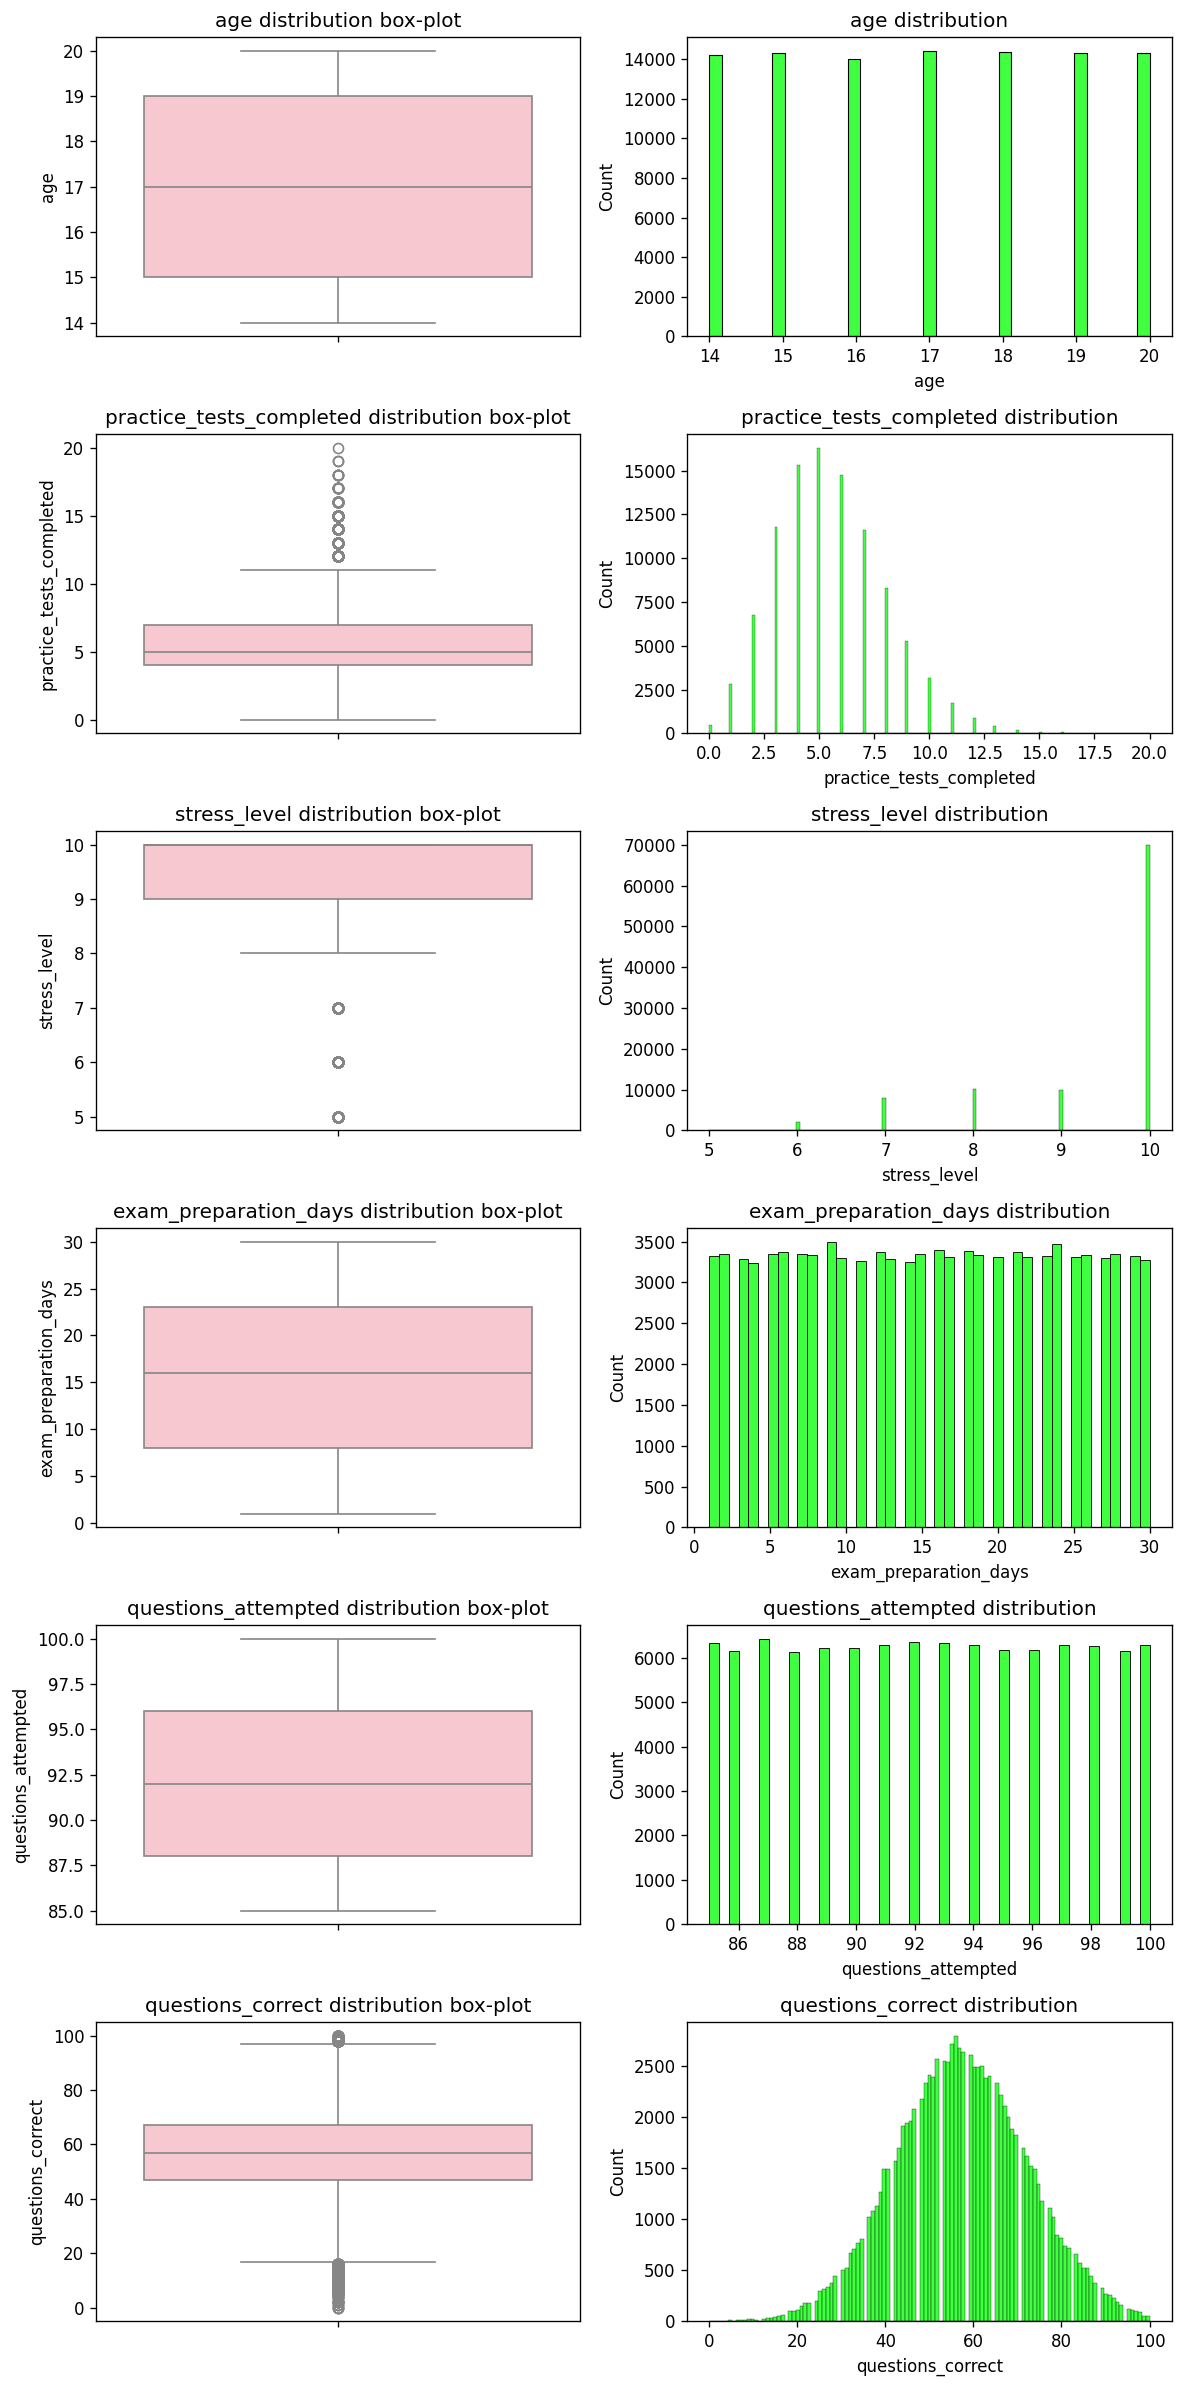

In [11]:
# histogram and boxplot of numeric columns 
numerical = df.select_dtypes('int64', 'float64').columns.to_list()
numerical = [num for num in numerical if num not in ['internet_access', 'private_tuition']] # ordinal categorical variables that is not in span of task

fig, ax = plt.subplots(nrows=len(numerical), ncols=2, figsize=(10, 20), dpi=120)
ax = ax.flatten('F')
for num, i in zip(numerical, range(0, len(ax))):
    sns.boxplot(
        data=df[num],
        color='pink',
        ax=ax[i]
    )
    title = num + ' distribution box-plot'
    ax[i].set_title(title)
    set = i + 1
for num, i in zip(numerical, range(set, len(ax))):
    sns.histplot(
        data=df[num],
        color='lime',
        ax=ax[i]
    )
    title = num + ' distribution'
    ax[i].set_title(title)

plt.tight_layout()
plt.show()

In [12]:
# checking skew in numerical columns
display(df[numerical].skew())

age                        -0.005507
practice_tests_completed    0.536595
stress_level               -1.582138
exam_preparation_days      -0.001138
questions_attempted         0.001491
questions_correct          -0.008013
dtype: float64

My regression target is exam_score, let's see if it's distribution is skewed:

In [13]:
display(df['exam_score'].skew())

np.float64(-0.057090225644788835)

The skewness coefficient is -0.06, which, with a certain degree of statistical significance, can be considered not skewed.

### Task 2. Regression
Train a Simple Linear Regression (one feature) and a Multiple Regression (at least 3features) to predict your continuous target. Evaluate both with R², RMSE, and MAE, andstate which model performs better and by how much

In [14]:
# simple linear regression

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

lr = LinearRegression()
X = df['questions_correct'].values.reshape(-1, 1)
y = df['exam_score'].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
print('R^2 score is:', r2_score(y_test, y_pred))
print('Mean squared erros is:', mean_squared_error(y_test, y_pred))
print('Mean absolute error is:', mean_absolute_error(y_test, y_pred))

R^2 score is: 0.9514303446948189
Mean squared erros is: 12.297515198876543
Mean absolute error is: 2.8750903640684724


In [15]:
# multiple regression

X = df[['practice_tests_completed', 'stress_level', 'exam_preparation_days']].values.reshape(-1, 3)
y = df['exam_score'].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
print('R^2 score is:', r2_score(y_test, y_pred))
print('Mean squared erros is:', mean_squared_error(y_test, y_pred))
print('Mean absolute error is:', mean_absolute_error(y_test, y_pred))

R^2 score is: 0.1622498033373858
Mean squared erros is: 209.42957659154385
Mean absolute error is: 11.607893891319048


First model with simple regression outperformed second with more features, because questions_correct feature strongly correlates with exam_score.
Judging by R^2, simple regression predicts by average 5.5 times better than multiple.

### Task 3. Classification
Following the classification steps from the lecture (prepare data, select features, split intotrain/test, choose and train a model, evaluate), build a classifier for your categorical target using any algorithm from the lecture's list (e.g. Logistic Regression or Decision Tree).Report accuracy, precision, recall, and F1 score

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils import column_or_1d
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import chi2
from sklearn.svm import SVC

In [17]:
# data_preprocessing, scaling
targets = ['pass_status']
features_num = df_copy.select_dtypes(['int64', 'float64']).drop('exam_score', axis=1).columns.to_list() 
features_cat = df_copy.select_dtypes(['object']).drop(targets + ['student_id', 'performance_level'], axis=1).columns.to_list()

# nominal encoder
nom_feat = ['school_type', 'urban_rural', 'study_method', 'gender', 'device_availability'] # nominal features

# ordinal encoder
feat_mapping = { # mapping every feature and order
    'education_level' : ['High School', 'Undergraduate'],
    'family_income' : ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High'],
    'parent_education' : ['High School', 'Associate', 'Bachelor', 'Master', 'Doctorate'],
    'class_participation' : ['Low', 'Medium', 'High'],
    'study_consistency' : ['Low', 'Medium', 'High'],
    'study_environment' : ['Quiet', 'Moderate', 'Noisy'],
    'revision_frequency' : ['Rarely', 'Weekly', 'Daily'],
    'notes_quality' : ['Poor', 'Average', 'Excellent'],
    'sleep_quality' : ['Poor', 'Fair', 'Good', 'Excellent'],
    'break_frequency' : ['Rarely', 'Occasionally', 'Frequently'],
    'motivation_level' : ['Low', 'Medium', 'High'],
    'educational_app_usage' : ['Low', 'Moderate', 'High'],
    'exam_difficulty' : ['Easy', 'Medium', 'Hard'],
}

ord_categories = list(feat_mapping.values())
ord_feat = list(feat_mapping.keys()) # ordinal features

preprocessor = ColumnTransformer(
    transformers=[
        ('cat_nom', OneHotEncoder(), nom_feat),
        ('num', StandardScaler(), features_num),
        ('cat_ord', OrdinalEncoder(categories=ord_categories), ord_feat)
    ]
)

For estimating associate link between nominal data and pass status i will try to use Pearson tests or chi-squared-statistics.
And for association between nominal data and performance grade I will use Pearson's correlation coefficient.


In [18]:
# feature selection
targ_categories = [['Fail', 'Pass']]
y_encoded = pd.DataFrame(data=OrdinalEncoder(categories=targ_categories).fit_transform(df_copy[targets])) 

# nominal feature selection
nominal = pd.get_dummies(df_copy[nom_feat])
p_value = pd.DataFrame(data=chi2(nominal, y_encoded), index=['statistics', 'p-value'], columns=nominal.columns) 

# every feature selection, embedded method
X = df_copy[features_num + nom_feat + ord_feat]
X_encoded = pd.DataFrame(
    preprocessor.fit_transform(X),
    columns=preprocessor.get_feature_names_out(),
    index=X.index,
)

rf = RandomForestClassifier(n_jobs=-1, n_estimators=100)
ranking = pd.DataFrame(rf.fit(X_encoded, column_or_1d(y_encoded)).feature_importances_,
                        index=preprocessor.get_feature_names_out(),
                          columns=['Importance']).sort_values(by='Importance', ascending=True)

display('p-values:', p_value.loc['p-value'])
display(ranking)

'p-values:'

school_type_Charter              0.116179
school_type_Private              0.436234
school_type_Public               0.961082
urban_rural_Rural                0.268310
urban_rural_Suburban             0.871024
urban_rural_Urban                0.553299
study_method_Flashcards          0.174760
study_method_Group Study         0.132823
study_method_Practice Tests      0.689714
study_method_Self-Reading        0.079861
study_method_Summarizing         0.467291
gender_Female                    0.960647
gender_Male                      0.789236
gender_Other                     0.283159
device_availability_Dedicated    0.826150
device_availability_Shared       0.704923
Name: p-value, dtype: float64

,Importance
cat_nom__gender_Other,0.000442
num__internet_access,0.000865
cat_nom__school_type_Charter,0.001018
cat_nom__device_availability_Shared,0.001133
cat_nom__device_availability_Dedicated,0.001150
cat_nom__study_method_Self-Reading,0.001160
cat_nom__study_method_Summarizing,0.001191
cat_nom__study_method_Group Study,0.001194
cat_nom__study_method_Practice Tests,0.001210
cat_nom__urban_rural_Rural,0.001231


We can see that most of the nominal data not associate with pass status, I will eliminate device_availability and gender. Random forest classifier selected only questions correct as somewhat important, and also there's no correlation between points. I assume SVM with RBF Kernel will be suitable for this dataset.

In [ ]:
# preprocessor
nom_feat = ['school_type', 'urban_rural', 'study_method']

X = df_copy[features_num + nom_feat + ord_feat]
y_encoded = pd.DataFrame(data=OrdinalEncoder(categories=targ_categories).fit_transform(df_copy[targets]), columns=targets) 

preprocessor = ColumnTransformer(
    transformers=[
        ('cat_nom', OneHotEncoder(), nom_feat),
        ('num', StandardScaler(), features_num),
        ('cat_ord', OrdinalEncoder(categories=ord_categories), ord_feat)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, column_or_1d(y_encoded, warn=False))

pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('classifier', SVC())
    ]
)

pipeline.fit(X_train, y_train)


,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat_nom', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [20]:
# scoring
import sklearn.metrics as sm
y_pred = pipeline.predict(X_test)

f1 = sm.f1_score(y_test, y_pred)
accuracy = sm.accuracy_score(y_test, y_pred)
precision = sm.precision_score(y_test, y_pred)
recall = sm.recall_score(y_test, y_pred)

print(   
    'Accuracy:', accuracy, 
    '\nF1-score:', f1,
    '\nPrecision:', precision, 
    '\nRecall:', recall
)

Accuracy: 0.97496 
F1-score: 0.983816762318391 
Precision: 0.9819889559787377 
Recall: 0.9856513856513857


<Figure size 600x700 with 0 Axes>

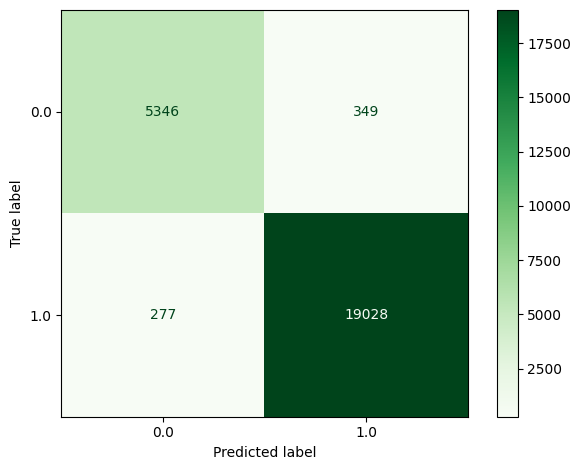

In [21]:
# Confusion matrix

fig = plt.figure(figsize=(6,7), dpi=100)

sm.ConfusionMatrixDisplay.from_predictions(
    y_true=y_test,
    y_pred=y_pred,
    cmap=plt.get_cmap('Greens')
)

plt.tight_layout()
plt.show()

Turns out SVM fitted data extremely well. 

In [22]:
del pipeline, y_pred

### Task 4. 

Clustering

4. Apply K-Means (a centroid-based, hard clustering method) to the numeric features of yourdataset. Try at least 3 different values of k, plot the resulting clusters on two features, and state whether the clusters appear to align with any categorical attribute in your data (e.g.do clusters roughly separate by category?).

In [23]:
# K-means
from sklearn.cluster import KMeans

# I decided not to use PCA because in my dataset it's not effective

num_scaled = df_copy.select_dtypes('number')
num_scaled = pd.DataFrame(data=StandardScaler().fit_transform(num_scaled), columns=num_scaled.columns)


clusters={} # dictionary with size mapped to respected KMeans estimator
sizes = [2, 3, 4, 5] 

for k in sizes:
    clusters[k] = KMeans(n_clusters=k, init='k-means++')


In [24]:
display(df_copy)

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,High School,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,79.00,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,High School,Suburban,73.40,2.89,84.75,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,High School,Suburban,78.73,2.78,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,Average,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,69.26,Medium,4.77,3.92,1,0.41,Medium,Quiet,Summarizing,Weekly,7,Average,8.37,Poor,4.40,2.21,Rarely,10,Medium,1,Shared,Moderate,0.55,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High


,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,sleep_hours,daily_screen_time,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
cluster,,,,,,,,,,,,,,,,,,,,,,
0,16.991141,75.324588,3.003205,85.936128,74.102092,3.883099,2.726902,0.301732,2.000199,6.409670,7.160615,5.008660,2.485822,9.210014,0.918573,2.993313,16.623849,92.809688,69.101767,79.507536,8.746800,74.461560
1,17.017868,64.717954,2.596075,83.544936,66.087580,2.258526,1.569983,0.298195,2.008555,4.761067,6.857599,4.993712,2.489038,9.513236,0.918915,3.004554,14.568983,92.228351,47.492292,77.583096,9.077386,51.555977


,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,sleep_hours,daily_screen_time,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
cluster,,,,,,,,,,,,,,,,,,,,,,
0,17.004849,61.966444,2.490880,83.439706,66.490336,2.312084,1.607763,0.296531,2.017240,4.785536,6.798978,4.991358,2.479415,9.573714,0.918127,2.989422,14.188983,92.180789,44.668291,77.171417,9.147782,48.518309
1,17.011465,77.836881,3.102820,85.200840,67.551599,2.352282,1.618483,0.304444,1.993219,5.215210,7.189488,5.015035,2.497895,9.136321,0.920511,3.010403,16.610335,92.772670,64.902986,79.674336,8.659474,69.971945
2,16.997920,69.880965,2.788201,85.904246,79.353874,5.336247,3.792671,0.298205,2.000618,7.345450,7.038883,4.993453,2.485718,9.402640,0.917040,3.000022,16.112302,92.608165,68.255120,78.835290,8.960058,73.711302


,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,sleep_hours,daily_screen_time,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
cluster,,,,,,,,,,,,,,,,,,,,,,
0,17.029828,69.960946,2.795678,84.730912,68.927762,2.745775,1.898952,0.304999,1.998905,5.376418,7.592041,4.966897,2.519158,7.303249,0.916958,2.974121,15.740653,92.614830,63.096905,79.869605,6.730491,68.126191
1,17.014057,78.075383,3.113111,85.177322,67.553532,2.340929,1.613446,0.301663,1.995777,5.191559,6.978375,5.020364,2.504913,9.780860,0.918199,3.028318,16.564512,92.696862,63.060119,79.076928,9.356970,68.043410
2,16.975400,70.270273,2.803254,85.939879,79.755650,5.475661,3.897311,0.298444,2.003223,7.441554,6.994403,4.996221,2.467398,9.613340,0.918416,2.973875,16.169226,92.621749,68.546433,78.872717,9.180915,74.013849
3,17.004928,61.099186,2.457161,83.363151,66.511482,2.331707,1.623472,0.296698,2.016278,4.789349,6.765173,4.998434,2.469797,9.725261,0.920206,2.997481,14.058239,92.182151,43.414155,77.075107,9.297100,47.156254


,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,sleep_hours,daily_screen_time,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
cluster,,,,,,,,,,,,,,,,,,,,,,
0,17.018017,61.657500,2.473069,86.195757,75.317260,3.741013,2.625560,0.287540,2.030987,6.145753,6.873278,5.024424,2.371351,9.759657,0.919070,3.033197,15.824920,92.332681,54.236034,78.096056,9.323941,58.763049
1,16.998079,79.114768,3.153430,85.073584,67.181548,2.303666,1.587824,0.304999,1.980733,5.158015,6.989431,5.024194,2.507085,9.766269,0.920548,3.029860,16.615264,92.750151,63.794094,79.140138,9.346709,68.796433
2,17.012303,62.462799,2.512311,82.189625,63.183316,1.876414,1.298945,0.299582,2.016368,4.333466,6.735661,4.988376,2.538850,9.709775,0.918853,2.969587,13.425244,92.139996,40.954808,76.867831,9.284508,44.526123
3,17.026236,69.836465,2.790144,84.656615,68.625973,2.687519,1.858189,0.304149,1.996058,5.323384,7.605690,4.962595,2.519730,7.271354,0.918638,2.976634,15.713022,92.602181,62.758567,79.888767,6.692201,67.771077
4,16.968325,74.602227,2.970947,85.919106,80.393654,5.852076,4.177016,0.303770,2.002141,7.770687,7.063803,4.974206,2.495543,9.480369,0.914281,2.961590,16.390036,92.754732,74.219381,79.129129,9.042672,80.039798


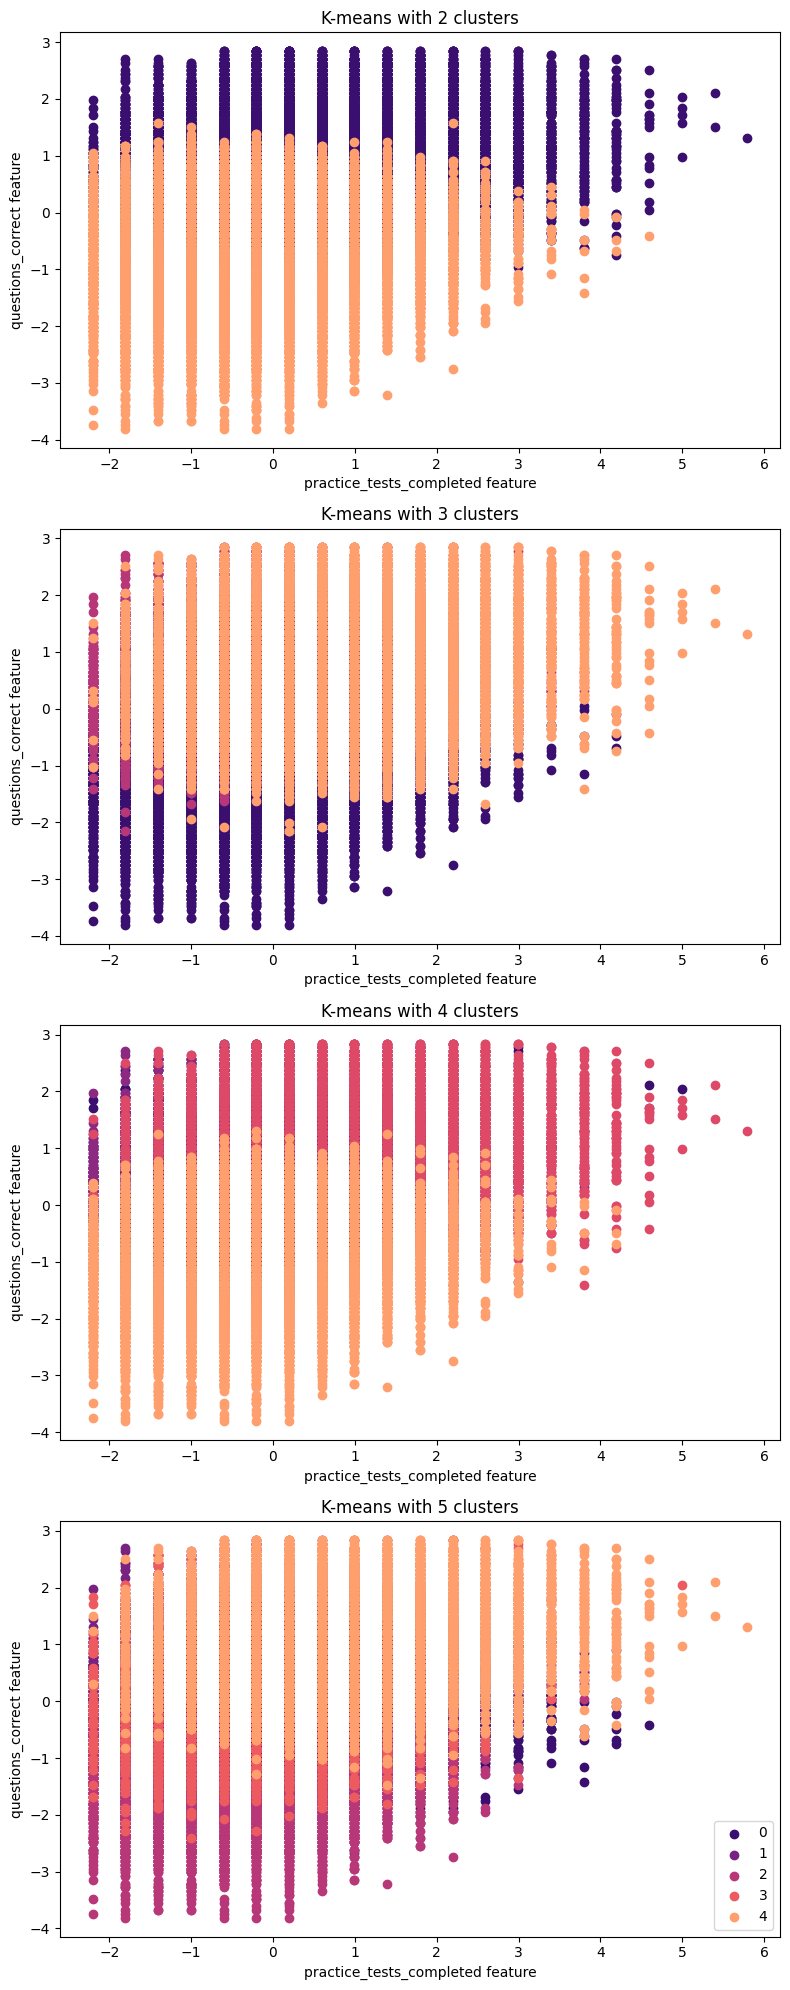

In [25]:
# plotting clusters 
fig, ax = plt.subplots(nrows=4, figsize=(8, 20), dpi=100)

for rowidx, k in enumerate(clusters):
    label = clusters[k].fit_predict(num_scaled)
    unique_labels = np.unique(label)

    # 
    df_copy['cluster'] = clusters[k].labels_
    cluster_profile = df_copy.groupby('cluster')[num_scaled.columns].mean()
    display(cluster_profile)
    df_copy.drop('cluster', axis=1, inplace=True)

    for idx, i in enumerate(unique_labels): # 
        ax[rowidx].scatter(
            num_scaled.loc[label==i, 'practice_tests_completed'],
            num_scaled.loc[label==i, 'questions_correct'],
            label=str(i),
            color= plt.cm.magma(np.linspace(0.2, 0.8, len(unique_labels)))[idx]
        )
        title = 'K-means with ' + str(k) + ' clusters'
        ax[rowidx].set_title(title)
        ax[rowidx].set_xlabel('practice_tests_completed feature')
        ax[rowidx].set_ylabel('questions_correct feature')


plt.tight_layout()
plt.legend()
plt.show()

K-Means with 2 cluster's means for 3 features varies sufficiently, 'previous_exam_score', 'previous_gpa' and 'exam_score' can be roughly interpreted as 'Fail', 'Pass'

Actually, all of cluster's means vary in a way that interpetes as our target variables.

## Part 2. Logistic regression. SVM. K-Nearest Neighbors (KNN) Classifier. Decision Tree Classifier. Model Estimation
### Task 5. Logistic Regression
Train a Logistic Regression model on your categorical (binary) target. Report the predicted probability (sigmoid output) for 5 individual test rows alongside their actual class, applythe 0.5 threshold rule from the lecture to get the predicted class, and report the AUC-ROCscore.

In [97]:
pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000))
    ]
)

targets = ['performance_grade']

targ_categories = [['F', 'D', 'C', 'B', 'A']]
y_encoded = pd.DataFrame(data=OrdinalEncoder(categories=targ_categories).fit_transform(df_copy[targets])) 

X_train, X_test, y_train, y_test = train_test_split(X, column_or_1d(y_encoded, warn=False), test_size=0.2)

pipeline.fit(X_train, y_train)



,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat_nom', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
test = X_test.reset_index(drop=True).sample(5) # predicting 5 rows
target_true = y_test[test.index]


In [172]:
target_pred = pipeline.predict(test)
target_pred_proba = pipeline.predict_proba(test)

for target, real_value, i in zip(target_pred, target_true, range(0, len(test))):
    print(f'For target {targ_categories[0][int(real_value)]} predicted value is {targ_categories[0][int(target)]} with {sorted(target_pred_proba[i, :], reverse= True)[0] * 100}% prob score')

For target D predicted value is D with 99.7944281240751% prob score
For target B predicted value is B with 63.29895036827271% prob score
For target D predicted value is D with 78.2865501111369% prob score
For target D predicted value is D with 98.48201095723681% prob score
For target B predicted value is B with 84.83725435528979% prob score


In [197]:
# ROC-AUC report
from sklearn.metrics import roc_auc_score

y_pred_proba = pipeline.predict_proba(X_test)

roc_auc = roc_auc_score(y_test, y_pred_proba, multi_class='ovr') # one vs rest multiclass ROC-AUC
display(roc_auc)


0.992201386026631

ROC-AUC score is 0.992, I didn't plot ROC-AUC curve because I decided to predict multiclass model, in this case there's multiple ROC curves for every class vs class.


### Task 6. Support Vector Machine
6. Train an SVM classifier with a Linear kernel and, separately, with an RBF kernel (the twokernel types covered in the lecture) on your categorical target. Report the number ofsupport vectors and the test accuracy for each, and state which kernel performed better.

In [200]:
RBFK_pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('classifier', SVC(kernel='rbf'))
    ]
)
LinearK_pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('classifier', SVC(kernel='linear'))
    ]
)

targets = ['performance_grade']
targ_categories = [['F', 'D', 'C', 'B', 'A']]

y_encoded = pd.DataFrame(data=OrdinalEncoder(categories=targ_categories).fit_transform(df_copy[targets])) 

X_train, X_test, y_train, y_test = train_test_split(X, column_or_1d(y_encoded, warn=False), test_size=0.2)



In [ ]:
RBFK_pipeline.fit(X_train, y_train) # training RBF kernel model

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat_nom', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
LinearK_pipeline.fit(X_train, y_train) # training Linear Kernel model

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat_nom', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [215]:
# predicting for test list

y_pred_lin = LinearK_pipeline.predict(X_test)
y_pred_rbf = RBFK_pipeline.predict(X_test)

In [ ]:
rbfk_svc = RBFK_pipeline.named_steps['classifier']
linear_svc = LinearK_pipeline.named_steps['classifier']

display(rbfk_svc.n_support_, linear_svc.n_support_) # for each class

array([4355, 9963, 9865, 6833, 2474], dtype=int32)

array([2398, 5558, 5484, 3437, 1112], dtype=int32)

RBF can be overfitted judging by amount of support vectors on each class

In [225]:
display(y_pred_lin)
kernels = {'Linear' : y_pred_lin, 'RBF' : y_pred_rbf}

for y_pred in kernels:
    f1 = sm.f1_score(y_test, kernels[y_pred], average='weighted')
    accuracy = sm.accuracy_score(y_test, kernels[y_pred])
    precision = sm.precision_score(y_test, kernels[y_pred], average='weighted')
    recall = sm.recall_score(y_test, kernels[y_pred], average='weighted')

    print(   
        f'For {y_pred} kernel',
        '\nAccuracy:', accuracy,
        '\nF1-score:', f1,
        '\nPrecision:', precision, 
        '\nRecall:', recall
    )

array([2., 0., 2., ..., 3., 0., 2.], shape=(20000,))

For Linear kernel 
Accuracy: 0.91005 
F1-score: 0.9100939998132953 
Precision: 0.9101831262481587 
Recall: 0.91005
For RBF kernel 
Accuracy: 0.90145 
F1-score: 0.9015992567985582 
Precision: 0.9020022941772491 
Recall: 0.90145


Linear kernel did better job and got 91% accuracy, F1, Recall, Precision

### Task 7. K-Nearest Neighbors
7. Using Euclidean distance, train a KNN classifier for your categorical target. Apply theElbow Method from the lecture: plot the error rate for k = 1 to 20 (odd values only, asrecommended in the lecture) and report the k value where the curve bends and the testaccuracy at that k.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

targets=['pass_status']
targ_categories = [['Fail', 'Pass']] # targets

X = df_copy[features_num + nom_feat + ord_feat] # data with features selected
y_encoded = pd.DataFrame(data=OrdinalEncoder(categories=targ_categories).fit_transform(df_copy[targets]), columns=targets)  

X_train, X_test, y_train, y_test = train_test_split(X, column_or_1d(y_encoded, warn=False), test_size=0.2) # data splitting 

array([[1.],
       [1.],
       [1.],
       ...,
       [1.],
       [1.],
       [1.]], shape=(100000, 1))

In [250]:
accuracies = {}

for k in range(1, 21, 2):
    pipeline = Pipeline(
        steps = [
            ('preprocessor', preprocessor),
            ('classifier', KNeighborsClassifier(n_neighbors=k, metric='euclidean'))
        ]
    )
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    accuracy = sm.accuracy_score(y_test, y_pred)
    accuracies[k] = accuracy


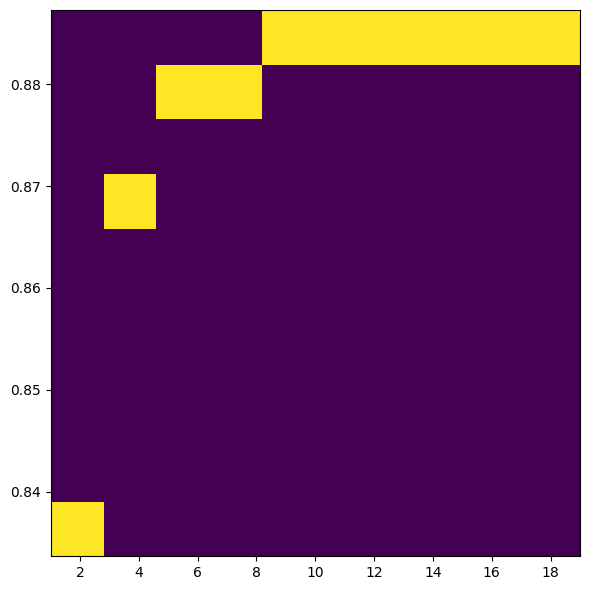

In [263]:
figure = plt.figure(figsize=(6,6), dpi=100)

plt.hist2d(
    x=accuracies.keys(),
    y=accuracies.values()
)

plt.tight_layout()
plt.show()

After K=10 curve bends, leaving ~0.9 accuracy at tests

### Task 8. Decision Tree
8. Train a Decision Tree classifier for your categorical target. For the root node's chosen split,manually compute the entropy of the dataset before the split and the Information Gain ofthat split using the formulas from the lecture, and confirm it matches (or is close to) what scikit-learn selected as the root feature.

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
# entropy(S) = -sum(p_i * log2(p_i))

# entropy for target
probabilities_target = df_copy['pass_status'].value_counts()/len(df_copy)
entropy_target = -sum(probabilities_target * np.log2(probabilities_target))

gain = {}

for i in (features_num + nom_feat + ord_feat):
    column = X_train[i]
    if (column.nunique() > 10): # discretization 
        column = pd.qcut(column, 10, duplicates='drop')

    contingency = pd.crosstab(column, y_train, normalize='index')   
    contingency = np.clip(contingency, 1e-9, 1.0)
    prob_cat = column.value_counts(normalize=True)

    entropy_per_cat = -np.sum(contingency * np.log2(contingency), axis=1)
    entropy_target_feat = np.sum(entropy_per_cat * prob_cat.reindex(entropy_per_cat.index, fill_value=0))

    gain[i] = entropy_target - entropy_target_feat


In [488]:
best_feature = max(gain, key=gain.get)
max_gain = gain[best_feature] 

print('Feature that we should use:', best_feature, '\nit\'s gain:', max_gain)
print('Entropy for target (pass status):', entropy_target)

Feature that we should use: questions_correct 
it's gain: 0.6065924035429737
Entropy for target (pass status): 0.771168279195823


In [516]:
pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier',  DecisionTreeClassifier(criterion='entropy'))
    ]
)
pipeline.fit(X_train, y_train) # training on splitted 0.8/0.2 data where 0.8 is training split
tree = pipeline.named_steps['classifier']


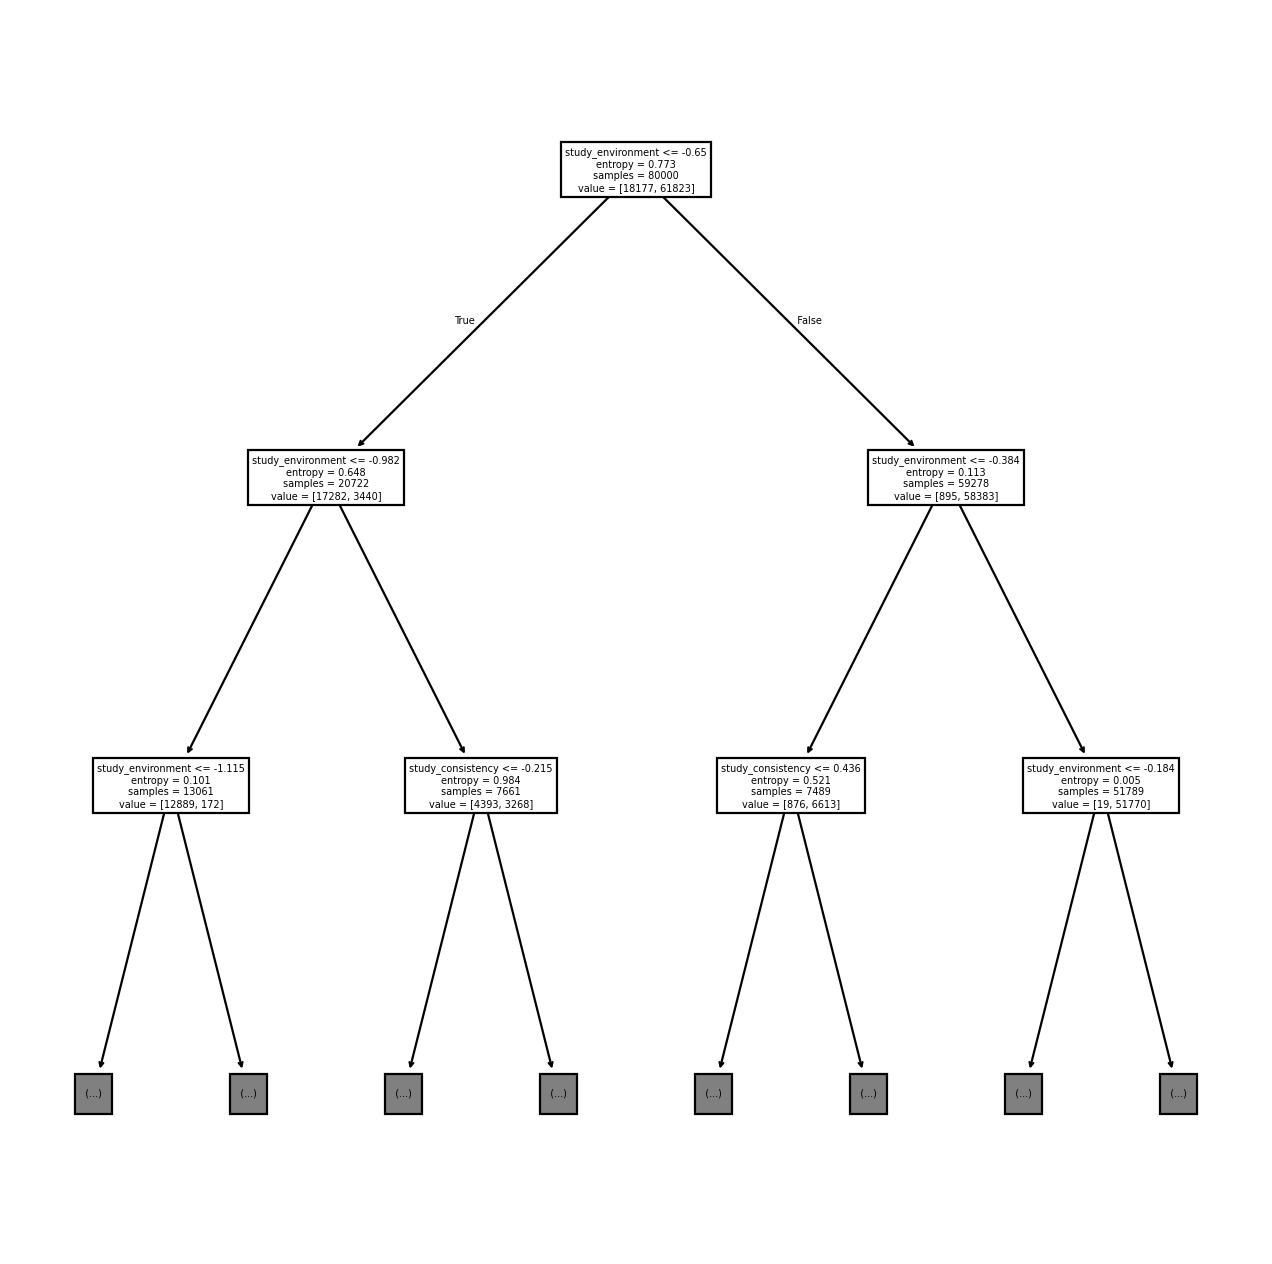

In [517]:
# tree drawing
figure = plt.figure(figsize=(10, 10), dpi=160)
plot_tree(decision_tree=tree, feature_names=X_train.columns, max_depth=2)
plt.show()

As we can see best features didn't fit, but entropy's values are very close. I suppose it is because my implementation's numerical values are discretized. As we know decision tree is veey unstable to sample changing when learning, so it is very likely the reason.